# Módulo 17: Metodología — Solución

> Solución de referencia de la guía [m17-metodologia-guia.ipynb](m17-metodologia-guia.ipynb). No es una tarea entregada del programa.

Lección: [m17-metodologia-leccion.md](m17-metodologia-leccion.md)

## Contexto

**Transvalores del Valle** es una empresa ficticia de transporte de valores que reabastece de efectivo los cajeros automáticos de un banco regional. Cada mañana, un camión blindado sale de la base de la empresa, visita los cajeros que el banco marcó con **alerta de efectivo bajo** y regresa a la base.

Hoy los custodios visitan los cajeros **en el orden en que llegaron las alertas**. El resultado son jornadas largas, horas extra, más combustible y más kilómetros con efectivo a bordo, que es justo cuando el camión está más expuesto. Además, el banco exige que los cajeros del distrito financiero se reabastezcan **antes de las 11:00**, porque al mediodía tienen su pico de retiros.

La gerencia de operaciones pide plantear el proyecto con una metodología de ciencia de datos y construir una prueba de concepto con las alertas de un día típico.

## Datos

La celda inicial genera, con una semilla fija, las 15 alertas de un día en el DataFrame `cajeros` y la ubicación de la base en `base`. Las coordenadas están en kilómetros sobre un plano de la ciudad.

| Columna | Descripción |
| --- | --- |
| `cajero` | Identificador del cajero (`C01` a `C15`) |
| `orden_alerta` | Orden en que llegó la alerta de efectivo bajo (1 = la primera) |
| `zona` | Zona de la ciudad: `Norte`, `Centro` u `Oriente` |
| `x_km`, `y_km` | Coordenadas del cajero (km) |
| `servicio_min` | Minutos que tarda el reabastecimiento en el cajero |
| `antes_11h` | `True` si el cajero debe reabastecerse antes de las 11:00 |

`base` es una tupla `(x_km, y_km)` con la ubicación de la base de la empresa. Supuestos de operación: salida de la base a las **7:00**, velocidad media de **25 km/h** y distancia en línea recta entre puntos.

## Instrucciones

1. **Objetivo de negocio y KPIs.** Redactar el objetivo, proponer KPIs medibles y explicar el papel de la minería de datos.
2. **Datos necesarios y fuentes.** Listar los datos de un sistema real, sus fuentes y su preparación, y lo que falta en `cajeros`.
3. **Riesgos de implementación y aceptación del cliente.** Identificar riesgos y explicar cómo lograr la aceptación.
4. **Matriz de distancias y ruta de referencia.** Calcular la matriz euclidiana, la función `distancia_total` y la distancia de la ruta por orden de alerta.
5. **Heurística del vecino más cercano.** Implementarla y calcular el ahorro frente a la referencia.
6. **Mejora 2-opt y comparación del KPI.** Mejorar la ruta con 2-opt, estimar horarios y comparar distancia, ahorro y jornada.
7. **Gráfico de las rutas y límites de la heurística.** Dibujar las rutas, revisar las franjas de las 11:00 y discutir los límites.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Tres zonas con cajeros agrupados alrededor de un centro (x, y) en km
zonas = {"Norte": ((6, 16), 5), "Centro": ((11, 9), 6), "Oriente": ((17, 4), 4)}
filas = []
for zona, ((cx, cy), n) in zonas.items():
    for x, y in rng.normal([cx, cy], 1.6, size=(n, 2)):
        filas.append({"zona": zona, "x_km": round(x, 2), "y_km": round(y, 2)})

# Las alertas llegan en un orden que no tiene relación con la ubicación
cajeros = pd.DataFrame(filas).sample(frac=1, random_state=42).reset_index(drop=True)
cajeros.insert(0, "orden_alerta", np.arange(1, len(cajeros) + 1))
cajeros.insert(0, "cajero", [f"C{i:02d}" for i in range(1, len(cajeros) + 1)])
cajeros["servicio_min"] = rng.choice([10, 15, 20, 30], size=len(cajeros), p=[0.25, 0.4, 0.25, 0.1])
cajeros["antes_11h"] = False
cajeros.loc[rng.choice(len(cajeros), 4, replace=False), "antes_11h"] = True

base = (3.0, 3.0)

print("Base:", base)
cajeros

Base: (3.0, 3.0)


,cajero,orden_alerta,zona,x_km,y_km,servicio_min,antes_11h
0,C01,1,Centro,12.41,8.92,20,False
1,C02,2,Oriente,18.96,3.75,30,False
2,C03,3,Norte,6.49,14.34,15,False
3,C04,4,Oriente,17.85,4.58,15,False
4,C05,5,Centro,12.41,10.24,15,False
5,C06,6,Centro,11.59,7.47,10,True
6,C07,7,Norte,2.88,13.92,10,False
7,C08,8,Norte,7.20,17.50,15,False
8,C09,9,Oriente,17.66,4.69,10,False
9,C10,10,Norte,5.97,14.64,20,False


Las 15 alertas se reparten en tres zonas: cinco en el Norte, seis en el Centro y cuatro en el Oriente. El orden de llegada de las alertas salta de una zona a otra (`Centro`, `Oriente`, `Norte`, `Oriente`…), así que seguirlo al pie de la letra obliga a cruzar la ciudad varias veces. Los cuatro cajeros con `antes_11h` están en el Centro, el distrito financiero.

### Tarea 1. Objetivo de negocio y KPIs

**Objetivo de negocio.** Reducir los kilómetros y la duración de la ruta diaria de reabastecimiento, cumpliendo siempre la franja de las 11:00 del distrito financiero, para bajar el costo por visita (combustible y horas extra), acortar el tiempo que el efectivo pasa en tránsito y evitar que los cajeros se queden sin dinero.

El objetivo habla del negocio (costo, servicio al banco y seguridad), no del algoritmo. Elegir el vecino más cercano, 2-opt o programación lineal es una decisión posterior.

**KPIs medibles**

| KPI | Cálculo | Unidad |
| --- | --- | --- |
| Distancia por ruta | Suma de los km recorridos por el camión desde que sale hasta que vuelve a la base | km por ruta y día |
| Duración de la jornada | Hora de regreso a la base − hora de salida | horas; también horas extra por semana |
| Cumplimiento de franja | Cajeros con franja atendidos a tiempo / cajeros con franja | % |
| Tiempo de cajero sin efectivo | Horas entre que un cajero se queda vacío y su reabastecimiento | horas por cajero y mes |
| Costo por visita | (Combustible + horas de custodios + mantenimiento) / cajeros atendidos | moneda por visita |
| Km con efectivo a bordo | Km recorridos con carga, ponderados por el monto transportado | km |

Cada KPI necesita una **línea base** medida con la práctica actual (ruta por orden de alerta) y una meta. Por ejemplo, "reducir un 30 % los km por ruta en tres meses sin bajar del 100 % de cumplimiento de franja".

**Papel de la minería de datos.** Calcular una ruta corta para un día concreto es un problema de optimización. La minería de datos aporta lo que la optimización necesita y no conoce de antemano, como enumera la lección:

- **Analizar el historial** de rutas, GPS y alertas para medir los tiempos reales de traslado y de servicio por cajero, en lugar de suponer 25 km/h para todo el día.
- **Encontrar patrones**: qué cajeros se vacían cada viernes o antes de una quincena, qué tramos se congestionan a ciertas horas.
- **Predecir**: estimar la demanda de efectivo de cada cajero para anticipar las alertas y el tiempo de trayecto de cada tramo según la hora. Con esas predicciones la ruta se planifica la noche anterior, no a medida que llegan las alertas.

### Tarea 2. Datos necesarios y fuentes

| Conjunto de datos | Contenido | Fuente | Preparación necesaria |
| --- | --- | --- | --- |
| Catálogo de cajeros | Identificador, dirección, coordenadas, horario de acceso, capacidad de las gavetas | Banco | Geocodificar direcciones, unificar identificadores con los de la empresa, validar coordenadas fuera de la ciudad |
| Alertas y niveles de efectivo | Hora de la alerta, nivel de efectivo, retiros por hora | Sistema de monitoreo del banco | Unir con el catálogo por identificador, eliminar alertas duplicadas, convertir zonas horarias |
| Historial de rutas | Orden de visitas, horas de llegada y salida, km recorridos | GPS de los camiones y bitácora de los custodios | Limpiar puntos GPS erróneos, emparejar cada parada con su cajero, calcular tiempos de servicio reales |
| Red vial y tráfico | Distancias y tiempos por carretera entre cada par de puntos, por franja horaria | Proveedor externo de mapas | Construir matrices de distancia y tiempo por hora del día, revisar calles con acceso restringido para camiones |
| Flota y personal | Camiones, capacidad, límite de efectivo asegurado por viaje, turnos de custodios | Empresa (operaciones y recursos humanos) | Normalizar unidades y turnos, registrar vehículos fuera de servicio |
| Costos operativos | Costo por km, costo de la hora normal y extra, penalizaciones por incumplir la franja | Empresa (finanzas) y contrato con el banco | Actualizar los costos de forma periódica |

**Lo que falta en `cajeros`.** El conjunto del ejercicio tiene ubicaciones, tiempos de servicio y franjas, pero no tiene:

- distancias ni tiempos **por carretera**: usamos la línea recta, que subestima el recorrido real, sobre todo en una ciudad con calles de un solo sentido;
- **tráfico** por hora, de modo que 25 km/h es igual a las 7:00 que a las 13:00;
- el **monto** de efectivo de cada cajero y el **límite asegurado** del camión, que pueden obligar a volver a la base a recargar;
- el **horario de acceso** de cada cajero (por ejemplo, los de centros comerciales que abren a las 10:00);
- más de un camión: con varios vehículos el problema pasa a ser de **asignación y ruteo** a la vez.

### Tarea 3. Riesgos de implementación y aceptación del cliente

**Riesgos de implementación**

- **Integración con los sistemas existentes.** La ruta tiene que salir de las alertas del banco y llegar a los dispositivos de los custodios; si cada paso es una exportación manual, la solución no se usará a diario.
- **Calidad de los datos.** Coordenadas mal geocodificadas o tiempos de servicio irreales producen rutas imposibles, y una sola ruta absurda basta para perder la confianza de los custodios.
- **Seguridad.** En el transporte de valores, una ruta **predecible** es un riesgo: si el algoritmo siempre devuelve el mismo orden para los mismos cajeros, alguien puede anticiparlo. La solución debe permitir variar la ruta sin perder demasiada eficiencia.
- **Resistencia del personal.** Los custodios conocen la ciudad y pueden desconfiar de un sistema que ignora lo que ellos saben (una calle cerrada, un acceso complicado).
- **Cambios en la demanda y en la ciudad.** Obras, nuevos cajeros o cambios de horario hacen que el modelo pierda vigencia si no se monitorea y actualiza, tal como advierte la lección.

**Aceptación del cliente**

La lección insiste en demostrar el ahorro con pruebas rigurosas, comunicar los beneficios con claridad, involucrar al personal y darle capacitación y soporte. En este caso:

- **Piloto controlado.** Durante cuatro a seis semanas, una parte de los camiones usa la ruta sugerida y el resto sigue con la práctica actual. Se comparan los mismos KPIs de la Tarea 1 (km, jornada, cumplimiento de franja) en ambos grupos.
- **Custodios en el diseño.** Los jefes de ruta validan las primeras rutas y pueden reordenar una parada; cada ajuste manual se registra y sirve para mejorar el modelo.
- **Beneficios en términos de cada actor.** Para la gerencia, costo por visita; para los custodios, menos horas extra y jornadas más previsibles; para el banco, cumplimiento de la franja y menos horas de cajeros sin efectivo.
- **Transparencia.** Mostrar la ruta en un mapa con la distancia y la hora estimada de cada parada, en lugar de entregar solo una lista de cajeros.

### Tarea 4. Matriz de distancias y ruta de referencia

Primero apilamos la base y los 15 cajeros en un único arreglo. La base ocupa la fila 0, así que el cajero de la fila `i` de `cajeros` es el punto `i + 1`.

In [2]:
puntos = np.vstack([base, cajeros[["x_km", "y_km"]].to_numpy()])
print(puntos.shape)

# Diferencias entre todos los pares de puntos: arreglo de forma (16, 16, 2)
diferencias = puntos[:, None, :] - puntos[None, :, :]
D = np.sqrt((diferencias ** 2).sum(axis=2))

print("Forma de D:", D.shape)
print("¿Simétrica?", np.allclose(D, D.T))
print("¿Diagonal cero?", np.allclose(np.diag(D), 0))

nombres = ["Base"] + cajeros["cajero"].tolist()
pd.DataFrame(D, index=nombres, columns=nombres).iloc[:6, :6].round(2)

(16, 2)
Forma de D: (16, 16)
¿Simétrica? True
¿Diagonal cero? True


,Base,C01,C02,C03,C04,C05
Base,0.00,11.12,15.98,11.86,14.93,11.87
C01,11.12,0.00,8.34,8.03,6.96,1.32
C02,15.98,8.34,0.00,16.36,1.39,9.22
C03,11.86,8.03,16.36,0.00,14.98,7.20
C04,14.93,6.96,1.39,14.98,0.00,7.85
C05,11.87,1.32,9.22,7.20,7.85,0.00


La matriz es simétrica porque la distancia en línea recta de A a B es la misma que de B a A, y la diagonal es cero porque cada punto está a 0 km de sí mismo. Con distancias reales por carretera la matriz dejaría de ser simétrica: una calle de un solo sentido hace que ir y volver no midan lo mismo.

La función `distancia_total` suma los tramos consecutivos de una ruta. `etiquetas` traduce los índices a nombres para poder leer las rutas.

In [3]:
def distancia_total(ruta, D):
    """Suma de las distancias entre paradas consecutivas de la ruta."""
    return float(sum(D[a, b] for a, b in zip(ruta[:-1], ruta[1:])))


def etiquetas(ruta):
    """Ruta como texto: Base → C05 → ... → Base."""
    return " → ".join(nombres[i] for i in ruta)


# Ruta de referencia: los cajeros en el orden en que llegaron las alertas
orden = cajeros.sort_values("orden_alerta").index + 1   # fila i del DataFrame = punto i + 1
ruta_ref = [0] + orden.tolist() + [0]

print(etiquetas(ruta_ref))
print(f"Distancia de la ruta de referencia: {distancia_total(ruta_ref, D):.2f} km")

Base → C01 → C02 → C03 → C04 → C05 → C06 → C07 → C08 → C09 → C10 → C11 → C12 → C13 → C14 → C15 → Base
Distancia de la ruta de referencia: 160.99 km


La práctica actual recorre 160.99 km en línea recta para atender 15 cajeros, unos 10.7 km por cajero. Es nuestra línea base: todos los ahorros se miden contra ella.

### Tarea 5. Heurística del vecino más cercano

La heurística es **voraz** (*greedy*): en cada paso toma la mejor decisión local, el cajero más cercano, sin mirar las consecuencias para el resto de la ruta.

In [4]:
def vecino_mas_cercano(D, inicio=0):
    """Ruta que empieza en `inicio`, va siempre al punto no visitado más cercano y vuelve a `inicio`."""
    ruta = [inicio]
    pendientes = set(range(len(D))) - {inicio}
    while pendientes:
        actual = ruta[-1]
        siguiente = min(pendientes, key=lambda j: D[actual, j])
        ruta.append(siguiente)
        pendientes.remove(siguiente)
    return ruta + [inicio]


def ahorro_pct(d_ref, d_ruta):
    return (d_ref - d_ruta) / d_ref * 100


ruta_nn = vecino_mas_cercano(D)
d_ref = distancia_total(ruta_ref, D)
d_nn = distancia_total(ruta_nn, D)

print(etiquetas(ruta_nn))
print(f"Distancia del vecino más cercano: {d_nn:.2f} km")
print(f"Ahorro frente a la referencia: {ahorro_pct(d_ref, d_nn):.1f} %")

Base → C12 → C06 → C11 → C01 → C05 → C15 → C03 → C10 → C14 → C08 → C07 → C13 → C09 → C04 → C02 → Base
Distancia del vecino más cercano: 66.15 km
Ahorro frente a la referencia: 58.9 %


El vecino más cercano recorre **66.15 km** frente a 160.99 km: un ahorro del **58.9 %** con un algoritmo de pocas líneas. Lo que ahorra es, sobre todo, dejar de cruzar la ciudad entre zonas: atiende primero el Centro, después el Norte y al final el Oriente.

La ruta también muestra el defecto típico de una heurística voraz. Sus dos tramos más largos están al final: de C07, en el extremo oeste del Norte, salta al Oriente (C13, unos 17 km) y desde C02 vuelve a la base (casi 16 km). Juntos suman cerca de la mitad de la ruta. Al principio todas las decisiones son fáciles, y los puntos lejanos quedan para el final, cuando ya no hay alternativa.

### Tarea 6. Mejora 2-opt y comparación del KPI

**2-opt** parte de una ruta y busca pares de tramos que se puedan "descruzar". Invertir el segmento `ruta[i:j+1]` cambia solo dos tramos: `(ruta[i-1], ruta[i])` y `(ruta[j], ruta[j+1])` pasan a ser `(ruta[i-1], ruta[j])` y `(ruta[i], ruta[j+1])`. Por eso basta comparar esas cuatro distancias para saber si la inversión mejora la ruta. Los índices empiezan en 1 y terminan en `len(ruta) - 2` para que la base de los extremos no se mueva.

In [5]:
def dos_opt(ruta, D):
    """Mejora una ruta con 2-opt hasta que ninguna inversión la acorte."""
    ruta = list(ruta)
    mejora = True
    while mejora:
        mejora = False
        for i in range(1, len(ruta) - 2):
            for j in range(i + 1, len(ruta) - 1):
                cambio = (D[ruta[i - 1], ruta[j]] + D[ruta[i], ruta[j + 1]]
                          - D[ruta[i - 1], ruta[i]] - D[ruta[j], ruta[j + 1]])
                if cambio < -1e-9:
                    ruta[i:j + 1] = ruta[i:j + 1][::-1]
                    mejora = True
    return ruta


ruta_2opt = dos_opt(ruta_nn, D)
d_2opt = distancia_total(ruta_2opt, D)

print(etiquetas(ruta_2opt))
print(f"Distancia con 2-opt: {d_2opt:.2f} km")

# Comprobación: cada cajero aparece exactamente una vez en cada ruta
for r in (ruta_ref, ruta_nn, ruta_2opt):
    assert r[0] == r[-1] == 0 and sorted(r[1:-1]) == list(range(1, 16))

Base → C07 → C10 → C03 → C14 → C08 → C15 → C05 → C01 → C09 → C04 → C02 → C13 → C11 → C06 → C12 → Base
Distancia con 2-opt: 56.18 km


Para estimar horarios, la función `cronograma` avanza parada por parada: suma el tiempo de trayecto (distancia / 25 km/h) y, en cada cajero, los minutos de servicio. Devuelve la hora de llegada a cada cajero y la hora de regreso a la base, en minutos desde la medianoche.

In [6]:
VELOCIDAD_KMH = 25
SALIDA_MIN = 7 * 60            # 7:00
servicio = np.r_[0, cajeros["servicio_min"].to_numpy()]   # índice 0 = base, sin servicio


def cronograma(ruta, D):
    """Hora de llegada (min desde medianoche) a cada cajero y hora de regreso a la base."""
    reloj = SALIDA_MIN
    llegadas = {}
    for a, b in zip(ruta[:-1], ruta[1:]):
        reloj += D[a, b] / VELOCIDAD_KMH * 60
        if b != 0:
            llegadas[b] = reloj
            reloj += servicio[b]
    return llegadas, reloj


def hhmm(minutos):
    total = int(round(minutos))
    return f"{total // 60:02d}:{total % 60:02d}"


rutas = {"Referencia (orden de alerta)": ruta_ref,
         "Vecino más cercano": ruta_nn,
         "Vecino más cercano + 2-opt": ruta_2opt}

filas = []
for nombre, ruta in rutas.items():
    d = distancia_total(ruta, D)
    _, regreso = cronograma(ruta, D)
    filas.append({"ruta": nombre,
                  "distancia_km": round(d, 2),
                  "ahorro_pct": round(ahorro_pct(d_ref, d), 1),
                  "jornada_h": round((regreso - SALIDA_MIN) / 60, 2),
                  "regreso": hhmm(regreso)})

comparacion = pd.DataFrame(filas).set_index("ruta")
comparacion

,distancia_km,ahorro_pct,jornada_h,regreso
ruta,,,,
Referencia (orden de alerta),160.99,0.0,10.61,17:36
Vecino más cercano,66.15,58.9,6.81,13:49
Vecino más cercano + 2-opt,56.18,65.1,6.41,13:25


- **Distancia.** El vecino más cercano ahorra el 58.9 % de los km y 2-opt lo lleva al **65.1 %** (56.18 km): unos 10 km menos que el vecino más cercano en una sola ruta y un solo día. 2-opt elimina los dos tramos largos que dejó la heurística voraz: la ruta mejorada empieza por el Norte, baja por el Centro hasta el Oriente y regresa a la base pasando de nuevo por el Centro.
- **Jornada.** Con la práctica actual el camión vuelve a las 17:36, tras **10.6 horas**, lo que implica horas extra todos los días. Las dos rutas optimizadas regresan a las 13:49 y a las 13:25, con jornadas de 6.8 y 6.4 horas: **ambas caben en una jornada de 8 horas**. La diferencia entre ellas es de solo 24 minutos porque los 250 minutos de servicio en los cajeros no dependen de la ruta y pesan más que el trayecto (unos 135 minutos en la ruta 2-opt).
- **Lectura de negocio.** La línea base exagera el ahorro porque el orden de alertas es casi aleatorio respecto a la ubicación; un custodio con experiencia ya agruparía por zonas. Aun así, la comparación justifica el piloto: el KPI de distancia es medible y el ahorro es grande.

### Tarea 7. Gráfico de las rutas y límites de la heurística

Dibujamos las tres rutas en paneles con los mismos ejes: la base como un cuadrado negro, los cajeros coloreados por zona y los tramos en gris.

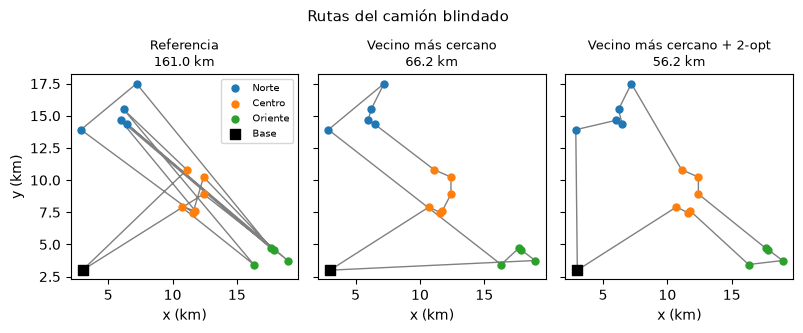

In [7]:
colores = {"Norte": "tab:blue", "Centro": "tab:orange", "Oriente": "tab:green"}

fig, ejes = plt.subplots(1, 3, figsize=(8, 3.2), sharex=True, sharey=True)
for ax, (nombre, ruta) in zip(ejes, rutas.items()):
    ax.plot(puntos[ruta, 0], puntos[ruta, 1], color="gray", linewidth=1, zorder=1)
    for zona, color in colores.items():
        en_zona = cajeros["zona"] == zona
        ax.scatter(cajeros.loc[en_zona, "x_km"], cajeros.loc[en_zona, "y_km"],
                   s=25, color=color, label=zona, zorder=2)
    ax.scatter(*base, marker="s", s=60, color="black", label="Base", zorder=3)
    ax.set_title(f"{nombre.split(' (')[0]}\n{distancia_total(ruta, D):.1f} km", fontsize=9)
    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")
ejes[0].set_ylabel("y (km)")
ejes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Rutas del camión blindado", fontsize=11)
fig.tight_layout()
plt.show()

El gráfico confirma la tabla. La referencia es una maraña de tramos que cruzan la ciudad de una zona a otra. El vecino más cercano agrupa por zonas, pero deja el salto del Norte al Oriente y el largo regreso desde el Oriente. La ruta 2-opt ya no tiene tramos cruzados: dibuja un circuito que sale de la base hacia el Norte y vuelve por el Centro.

Ahora revisamos la restricción que ninguna de las heurísticas tiene en cuenta: la franja de las 11:00. Añadimos además la ruta 2-opt recorrida en sentido contrario.

In [8]:
ruta_2opt_inv = [0] + ruta_2opt[1:-1][::-1] + [0]
rutas_franja = {**rutas, "2-opt en sentido contrario": ruta_2opt_inv}

con_franja = cajeros.index[cajeros["antes_11h"]] + 1      # puntos con franja
LIMITE_MIN = 11 * 60

filas = []
for nombre, ruta in rutas_franja.items():
    llegadas, _ = cronograma(ruta, D)
    horas = {nombres[p]: hhmm(llegadas[p]) for p in con_franja}
    tarde = sum(llegadas[p] > LIMITE_MIN for p in con_franja)
    filas.append({"ruta": nombre, "distancia_km": round(distancia_total(ruta, D), 2),
                  **horas, "tarde": tarde})

pd.DataFrame(filas).set_index("ruta")

,distancia_km,C06,C11,C12,C15,tarde
ruta,,,,,,
Referencia (orden de alerta),160.99,11:03,14:26,14:43,16:49,4
Vecino más cercano,66.15,07:44,07:55,07:22,08:55,0
Vecino más cercano + 2-opt,56.18,12:31,12:15,12:43,09:17,3
2-opt en sentido contrario,56.18,07:44,07:55,07:22,10:48,0


In [9]:
# 2-opt es una búsqueda local: el resultado depende de la ruta de partida
ruta_2opt_desde_ref = dos_opt(ruta_ref, D)
print(f"2-opt desde el vecino más cercano: {d_2opt:.2f} km")
print(f"2-opt desde la ruta de referencia: {distancia_total(ruta_2opt_desde_ref, D):.2f} km")

2-opt desde el vecino más cercano: 56.18 km
2-opt desde la ruta de referencia: 56.01 km


**Franja de las 11:00.** Los cuatro cajeros con franja (C06, C11, C12 y C15) están en el Centro.

- La referencia llega tarde a los **cuatro**.
- El vecino más cercano los atiende a tiempo, pero **por casualidad**: C12 es el cajero más cercano a la base y arrastra al resto del Centro al inicio de la ruta.
- La ruta 2-opt, la más corta, llega tarde a **tres** de los cuatro (C06, C11 y C12, después de las 12:00), porque los deja para el regreso.
- La **misma** ruta 2-opt recorrida al revés mide exactamente lo mismo, 56.18 km, y cumple las cuatro franjas.

La lección es que el KPI de distancia no basta: la ruta más corta puede ser inaceptable para el banco, y una restricción que el algoritmo no conoce se cumple o no por azar. Además, 2-opt es una **búsqueda local**: desde la ruta de referencia llega a 56.01 km, un poco menos que desde el vecino más cercano, así que ninguna de las dos es necesariamente la óptima.

**Límites de estas heurísticas para el caso real**

- **Distancia en línea recta y velocidad constante.** Las calles reales, los sentidos únicos y el tráfico de la hora punta cambian distancias y tiempos. Hace falta una matriz de tiempos por carretera y por franja horaria.
- **Sin ventanas de tiempo.** Ni el vecino más cercano ni 2-opt saben que hay cajeros con hora límite o con horario de acceso. Hay que incorporarlas como restricciones, con un problema de ruteo de vehículos con ventanas de tiempo (VRPTW, por sus siglas en inglés), resuelto con programación lineal entera o con metaheurísticas como el recocido simulado que menciona la lección.
- **Un solo camión y sin capacidad.** No se modelan el límite de efectivo asegurado ni el reparto de cajeros entre varios camiones.
- **Sin seguridad.** La ruta óptima es siempre la misma para el mismo conjunto de cajeros; en transporte de valores conviene introducir variación controlada.
- **Planificación estática.** La ruta se calcula una vez; en la operación real llegan alertas nuevas durante el día y la ruta debe recalcularse.

Para pasar a producción, además del algoritmo, hacen falta los datos de la Tarea 2, la integración con las alertas del banco y el piloto de la Tarea 3.

## Conclusiones

- Seguir el orden de llegada de las alertas cuesta caro: 161 km y 10.6 horas de jornada para 15 cajeros, con las cuatro franjas de las 11:00 incumplidas.
- Dos heurísticas sencillas reducen la distancia entre un 59 % y un 65 % y dejan la jornada por debajo de las 8 horas, lo que justifica un piloto medido con los KPIs de la Tarea 1.
- Optimizar solo la distancia no basta: la ruta más corta incumple tres franjas, mientras que la misma ruta en sentido contrario las cumple todas. Las restricciones del negocio deben entrar en el modelo, no comprobarse al final.
- El valor del proyecto depende tanto de los datos (tiempos por carretera, tráfico, demanda de efectivo) y de la aceptación de los custodios y del banco como del algoritmo; por eso la metodología empieza por el negocio y termina en la implementación.